- 데이터 확인
- 중복 데이터 확인
- 이상 데이터 확인
- 손상된 알약을 가진 이미지가 있을까??
- 이미지마다 알약은 몇개씩 있을까??
- 

## 데이터 로드

JSON 라벨 파일 하나와 연결된 이미지 한 장을 읽어 확인한다.
JSON은 이미지 파일명, 알약 위치(bbox), 종류 ID를 담은 라벨 파일이다.
아래 셀을 위에서부터 실행하면 `img`에 RGB 이미지, `annotations`에 라벨이 저장된다.
전체 데이터 로드는 아니며, 다른 JSON에 나뉜 같은 이미지의 라벨은 아직 합치지 않는다.

In [27]:
import json
from pathlib import Path

import cv2
import numpy as np

# 1. 프로젝트 최상위 폴더를 찾는다.
# 현재 폴더부터 상위 폴더까지 확인한다.
# src/config.py와 pyproject.toml이 함께 있는 곳을 프로젝트 루트로 판단한다.
PROJECT_ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "src" / "config.py").is_file() and (folder / "pyproject.toml").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("pill-bbox 프로젝트 안에서 노트북을 실행해 주세요.")

# 2. JSON 라벨 폴더와 이미지 폴더의 경로를 만든다.
annotation_dir = PROJECT_ROOT / "data" / "train_annotations"
image_dir = PROJECT_ROOT / "data" / "train_images"

# 3. 하위 폴더까지 탐색해서 JSON 파일 하나를 선택한다.
annotation_path = next(annotation_dir.rglob("*.json"), None)
if annotation_path is None:
    raise FileNotFoundError(f"JSON 라벨 파일이 없습니다: {annotation_dir}")

# 4. JSON 파일을 읽어 파이썬 딕셔너리로 바꾼다.
with annotation_path.open(encoding="utf-8") as file:
    data = json.load(file)

# 5. JSON에 기록된 첫 번째 이미지의 정보를 가져온다.
image_info = data["images"][0]

# 이미지 폴더 경로와 파일명을 합쳐 실제 이미지 경로를 만든다.
image_path = image_dir / image_info["file_name"]

# 6. 이미지 파일을 바이트 배열로 읽고, 이미지 배열로 변환한다.
# 이 방식은 한글이 포함된 경로에서도 이미지를 읽을 수 있게 한다.
img = cv2.imdecode(
    np.fromfile(image_path, dtype=np.uint8),
    cv2.IMREAD_COLOR,
)

# 파일을 이미지로 해석하지 못했다면 오류를 발생시킨다.
if img is None:
    raise ValueError(f"이미지를 읽을 수 없습니다: {image_path}")

# OpenCV 기본 색상 순서인 BGR을 RGB로 바꾼다.
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 7. JSON의 라벨 중 선택한 이미지에 연결된 것만 모은다.
annotations = [
    annotation for annotation in data["annotations"] if annotation["image_id"] == image_info["id"]
]

# 8. 읽은 결과를 확인한다.
print("이미지:", image_path.name)
print("이미지 크기:", img.shape)

for annotation in annotations:
    print("bbox:", annotation["bbox"])
    print("클래스:", annotation["category_id"])

이미지: K-001900-016548-019607-029451_0_2_0_2_70_000_200.png
이미지 크기: (1280, 976, 3)
bbox: [644, 845, 189, 190]
클래스: 1900


## 데이터별 파일 수 확인

앞의 데이터 로드 셀을 먼저 실행한다. 하위 폴더를 포함해 이미지와 JSON 파일 수를 센다.
JSON은 라벨 파일이므로 이미지 수와 다를 수 있다. 파일 내용은 읽지 않는다.

In [28]:
# 이미지 확장자는 대소문자 구분 없이 확인한다.
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

# 학습 이미지와 테스트 이미지 수를 각각 센다.
for folder_name in ("train_images", "test_images"):
    folder = PROJECT_ROOT / "data" / folder_name
    if not folder.is_dir():
        raise FileNotFoundError(f"데이터 폴더가 없습니다: {folder}")
    image_count = sum(
        1
        for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    print(f"{folder_name}: 이미지 {image_count:,}개")

# 라벨 JSON 수는 이미지 수와 구분해서 출력한다.
annotation_dir = PROJECT_ROOT / "data" / "train_annotations"
if not annotation_dir.is_dir():
    raise FileNotFoundError(f"라벨 폴더가 없습니다: {annotation_dir}")
annotation_count = sum(
    1 for path in annotation_dir.rglob("*") if path.is_file() and path.suffix.lower() == ".json"
)
print(f"train_annotations: JSON {annotation_count:,}개")

train_images: 이미지 232개
test_images: 이미지 842개
train_annotations: JSON 763개


## 학습·테스트 이미지 구조 비교
앞의 데이터 로드 및 파일 수 확인 셀을 먼저 실행한다.
폴더, 파일명, 확장자, 해상도, 색상 모드를 비교한다. 결과 전체는 `image_structure`에 저장한다.
파일명 숫자의 의미는 데이터 명세로 확인하기 전까지 추정하지 않는다.

In [34]:
from collections import Counter

import pandas as pd
from PIL import Image

# 전체 픽셀을 읽지 않고 이미지 헤더에서 크기와 색상 모드를 확인한다.
image_structure_rows = []
image_path_sets = {}
for split_name in ("train_images", "test_images"):
    split_dir = PROJECT_ROOT / "data" / split_name
    if not split_dir.is_dir():
        raise FileNotFoundError(f"이미지 폴더가 없습니다: {split_dir}")
    image_paths = sorted(
        path
        for path in split_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    image_path_sets[split_name] = {path.name for path in image_paths}
    print(f"\n[{split_name}]")
    print(f"이미지 수: {len(image_paths):,}장")
    print(f"하위 폴더 수: {sum(path.is_dir() for path in split_dir.rglob('*'))}")
    print(
        "이미지 상위 폴더별 수:",
        dict(Counter(path.parent.relative_to(split_dir).as_posix() for path in image_paths)),
    )
    print("확장자별 수:", dict(Counter(path.suffix.lower() for path in image_paths)))
    print("파일명 예시:", [path.name for path in image_paths[:3]])
    print("숫자로만 된 파일명 수:", sum(path.stem.isdecimal() for path in image_paths))
    print("K-로 시작하는 파일명 수:", sum(path.stem.startswith("K-") for path in image_paths))

    for path in image_paths:
        row = {"구분": split_name, "파일명": path.relative_to(split_dir).as_posix()}
        try:
            with Image.open(path) as image:
                row.update({"너비": image.width, "높이": image.height, "색상 모드": image.mode})
        except (OSError, ValueError) as error:
            row["읽기 오류"] = str(error)
        image_structure_rows.append(row)

    split_rows = [row for row in image_structure_rows if row["구분"] == split_name]
    print(
        "해상도별 수 (너비, 높이):",
        dict(Counter((row["너비"], row["높이"]) for row in split_rows if "읽기 오류" not in row)),
    )
    print(
        "색상 모드별 수:",
        dict(Counter(row["색상 모드"] for row in split_rows if "읽기 오류" not in row)),
    )
    print("헤더 읽기 오류 수:", sum("읽기 오류" in row for row in split_rows))

image_structure = pd.DataFrame(image_structure_rows)
shared_image_names = image_path_sets["train_images"] & image_path_sets["test_images"]
print(f"\ntrain/test에서 동일한 파일명: {len(shared_image_names)}개")
print("파일명이 달라도 같은 사진일 수 있으므로 이미지 내용 중복 여부는 별도 검사해야 한다.")
print("헤더 확인만으로 이미지 전체의 손상 여부나 촬영 조건 차이를 판단할 수는 없다.")


[train_images]
이미지 수: 232장
하위 폴더 수: 0
이미지 상위 폴더별 수: {'.': 232}
확장자별 수: {'.png': 232}
파일명 예시: ['K-001900-016548-019607-029451_0_2_0_2_70_000_200.png', 'K-001900-016548-019607-029451_0_2_0_2_75_000_200.png', 'K-001900-016548-019607-029451_0_2_0_2_90_000_200.png']
숫자로만 된 파일명 수: 0
K-로 시작하는 파일명 수: 232
해상도별 수 (너비, 높이): {(976, 1280): 232}
색상 모드별 수: {'RGB': 232}
헤더 읽기 오류 수: 0

[test_images]
이미지 수: 842장
하위 폴더 수: 0
이미지 상위 폴더별 수: {'.': 842}
확장자별 수: {'.png': 842}
파일명 예시: ['1.png', '10.png', '100.png']
숫자로만 된 파일명 수: 842
K-로 시작하는 파일명 수: 0
해상도별 수 (너비, 높이): {(976, 1280): 842}
색상 모드별 수: {'RGB': 842}
헤더 읽기 오류 수: 0

train/test에서 동일한 파일명: 0개
파일명이 달라도 같은 사진일 수 있으므로 이미지 내용 중복 여부는 별도 검사해야 한다.
헤더 확인만으로 이미지 전체의 손상 여부나 촬영 조건 차이를 판단할 수는 없다.


## 사진별 JSON 및 라벨 수 확인
앞의 두 코드 셀을 먼저 실행한다. 전체 JSON을 읽어 파일명으로 묶는다.
라벨 수는 원본 annotation 항목 수이며 실제 알약 수와 같은지는 중복 검사가 필요하다.

In [29]:
from collections import Counter

import pandas as pd

# 사진별 연결 관계를 확인하기 위해 이번에는 모든 JSON을 하나씩 읽는다.
# 이미지 픽셀은 읽지 않고, 파일명과 라벨 개수만 메모리에 저장한다.
image_json_paths = {}
image_label_counts = Counter()
json_count = 0
for annotation_path in annotation_dir.rglob("*"):
    if not annotation_path.is_file() or annotation_path.suffix.lower() != ".json":
        continue
    with annotation_path.open(encoding="utf-8") as file:
        annotation_data = json.load(file)
    json_count += 1
    image_names = {image["id"]: image["file_name"] for image in annotation_data["images"]}
    for image_name in image_names.values():
        image_json_paths.setdefault(image_name, set()).add(annotation_path)
    for label in annotation_data["annotations"]:
        # JSON 안의 image_id로 연결한다. 서로 다른 JSON의 ID를 직접 합치지 않는다.
        image_name = image_names[label["image_id"]]
        image_label_counts[image_name] += 1

# 실제 사진 파일과 JSON에서 참조한 파일을 비교한다.
image_dir = PROJECT_ROOT / "data" / "train_images"
actual_image_names = {
    path.relative_to(image_dir).as_posix()
    for path in image_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
}
referenced_image_names = set(image_json_paths)
missing_image_names = referenced_image_names - actual_image_names
unlabeled_image_names = actual_image_names - referenced_image_names

# 파일명이 같으면 같은 이미지로 묶는다. 라벨 개수는 중복 제거 전 원본 항목 수다.
image_summary = pd.DataFrame(
    [
        {
            "이미지 파일명": image_name,
            "JSON 수": len(image_json_paths.get(image_name, set())),
            "라벨 수(중복 제거 전)": image_label_counts[image_name],
            "이미지 파일 존재": image_name in actual_image_names,
        }
        for image_name in sorted(actual_image_names | referenced_image_names)
    ],
    columns=["이미지 파일명", "JSON 수", "라벨 수(중복 제거 전)", "이미지 파일 존재"],
)

print(f"읽은 JSON: {json_count:,}개")
print(f"JSON에서 참조한 서로 다른 이미지: {len(referenced_image_names):,}장")
print(f"실제 학습 이미지: {len(actual_image_names):,}장")
print(f"JSON은 참조하지만 사진 파일이 없는 이미지: {len(missing_image_names):,}장")
print(f"연결된 JSON이 없는 사진: {len(unlabeled_image_names):,}장")
print(f"전체 라벨 항목: {sum(image_label_counts.values()):,}개 (중복 제거 전)")

print("\n이미지별 연결된 JSON 수 분포:")
print(image_summary["JSON 수"].value_counts().sort_index().rename_axis("JSON 수").to_string())
print("\n사진별 결과 예시 10개 (전체 결과는 image_summary에 저장):")
print(image_summary.head(10).to_string(index=False))

읽은 JSON: 763개
JSON에서 참조한 서로 다른 이미지: 232장
실제 학습 이미지: 232장
JSON은 참조하지만 사진 파일이 없는 이미지: 0장
연결된 JSON이 없는 사진: 0장
전체 라벨 항목: 763개 (중복 제거 전)

이미지별 연결된 JSON 수 분포:
JSON 수
2      7
3    151
4     74

사진별 결과 예시 10개 (전체 결과는 image_summary에 저장):
                                             이미지 파일명  JSON 수  라벨 수(중복 제거 전)  이미지 파일 존재
K-001900-016548-019607-029451_0_2_0_2_70_000_200.png       4              4       True
K-001900-016548-019607-029451_0_2_0_2_75_000_200.png       4              4       True
K-001900-016548-019607-029451_0_2_0_2_90_000_200.png       4              4       True
K-001900-016548-019607-033009_0_2_0_2_70_000_200.png       4              4       True
K-001900-016548-019607-033009_0_2_0_2_75_000_200.png       4              4       True
K-001900-016548-019607-033009_0_2_0_2_90_000_200.png       4              4       True
K-001900-016548-021771-027926_0_2_0_2_70_000_200.png       4              4       True
K-001900-016548-021771-027926_0_2_0_2_75_000_200.png       4              

- train_annotations은 알약 종류뿐 아니라 사진 속 위치도 알려주는 정답 데이터
- 데이터는 사진 하나에 JSON이 여러 개 연결되어 있음
- 학습할 때는 같은 사진에 해당하는 라벨들을 모아줘야함

## 선택한 이미지에 연결된 JSON 모두 찾기
데이터 로드 셀을 먼저 실행한다. JSON 내부의 이미지 파일명을 기준으로 전체 라벨 폴더를 검색한다.
연결된 JSON 경로와 제품명, bbox를 출력하고 라벨을 모은다. 아래 시각화 셀은 모은 라벨 전체를 그린다.

In [30]:
# 앞의 데이터 로드 셀에서 선택한 사진을 기준으로 찾는다.
# 다른 사진을 확인하려면 이 값을 train_images 안의 파일명으로 바꾼다.
target_image_name = image_info["file_name"]
matched_json_paths = []
all_annotations = []

# JSON 파일명 대신 내부 images의 file_name을 비교해야 정확하게 연결할 수 있다.
for json_path in sorted(annotation_dir.rglob("*.json")):
    with json_path.open(encoding="utf-8") as file:
        json_data = json.load(file)

    # image_id는 JSON마다 다를 수 있으므로 현재 JSON 안에서 찾아 연결한다.
    matched_image_ids = {
        image["id"] for image in json_data["images"] if image["file_name"] == target_image_name
    }
    if not matched_image_ids:
        continue

    matched_json_paths.append(json_path)
    matched_annotations = [
        label for label in json_data["annotations"] if label["image_id"] in matched_image_ids
    ]
    category_names = {
        category["id"]: category.get("name", "이름 없음") for category in json_data["categories"]
    }
    all_annotations.extend(matched_annotations)

    print(f"\nJSON: {json_path.relative_to(PROJECT_ROOT)}")
    for label in matched_annotations:
        category_id = label["category_id"]
        print(
            f"  종류 ID: {category_id}, "
            f"제품명: {category_names.get(category_id, '이름 없음')}, "
            f"bbox: {label['bbox']}"
        )

print(f"\n대상 이미지: {target_image_name}")
print(f"연결된 JSON: {len(matched_json_paths)}개")
print(f"모은 라벨: {len(all_annotations)}개 (중복 제거 전)")

# 아래 시각화 셀에서 선택한 사진과 모은 라벨 전체를 사용한다.
image_path = image_dir / target_image_name
img = cv2.imdecode(np.fromfile(image_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if img is None:
    raise ValueError(f"이미지를 읽을 수 없습니다: {image_path}")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
annotations = all_annotations


JSON: data/train_annotations/K-001900-016548-019607-029451_json/K-001900/K-001900-016548-019607-029451_0_2_0_2_70_000_200.json
  종류 ID: 1900, 제품명: 보령부스파정 5mg, bbox: [644, 845, 189, 190]

JSON: data/train_annotations/K-001900-016548-019607-029451_json/K-016548/K-001900-016548-019607-029451_0_2_0_2_70_000_200.json
  종류 ID: 16548, 제품명: 가바토파정 100mg, bbox: [144, 799, 239, 239]

JSON: data/train_annotations/K-001900-016548-019607-029451_json/K-019607/K-001900-016548-019607-029451_0_2_0_2_70_000_200.json
  종류 ID: 19607, 제품명: 스토가정 10mg, bbox: [657, 287, 155, 150]

JSON: data/train_annotations/K-001900-016548-019607-029451_json/K-029451/K-001900-016548-019607-029451_0_2_0_2_70_000_200.json
  종류 ID: 29451, 제품명: 레일라정, bbox: [108, 218, 392, 264]

대상 이미지: K-001900-016548-019607-029451_0_2_0_2_70_000_200.png
연결된 JSON: 4개
모은 라벨: 4개 (중복 제거 전)


- 이미지 하나에 JSON이 모두 연결되어 있다는 것을 확인하기 위함

위치 정보: [644, 845, 189, 190]
종류 ID: 1900
위치 정보: [144, 799, 239, 239]
종류 ID: 16548
위치 정보: [657, 287, 155, 150]
종류 ID: 19607
위치 정보: [108, 218, 392, 264]
종류 ID: 29451


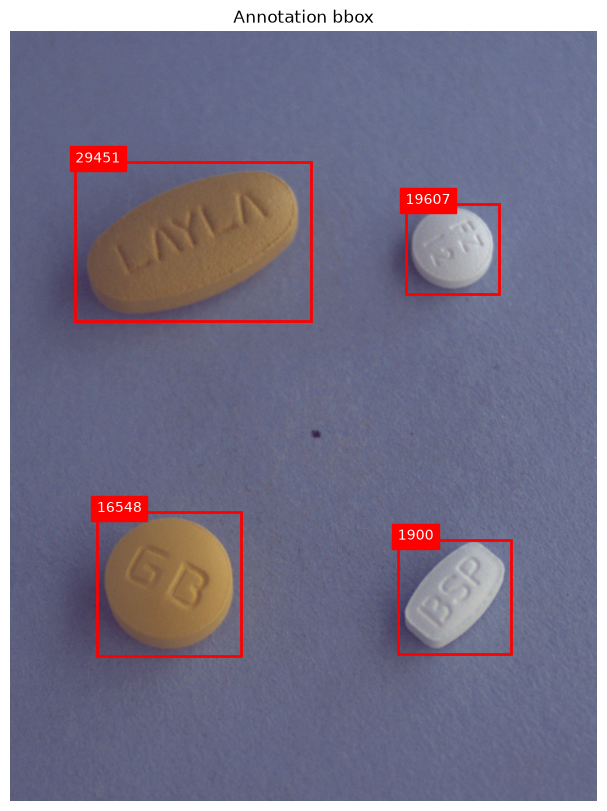

In [31]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# JSON에 위치와 종류 정보가 있는지 확인한다.
for annotation in annotations:
    print("위치 정보:", annotation.get("bbox"))
    print("종류 ID:", annotation.get("category_id"))

# 사진 위에 bbox를 그린다.
fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(img)

for annotation in annotations:
    # bbox를 [왼쪽 x, 위쪽 y, 너비, 높이] 형식으로 해석한다.
    left, top, width, height = annotation["bbox"]

    ax.add_patch(
        Rectangle(
            (left, top),
            width,
            height,
            edgecolor="red",
            facecolor="none",
            linewidth=2,
        )
    )
    ax.text(
        left,
        top,
        str(annotation["category_id"]),
        color="white",
        backgroundcolor="red",
    )

ax.set_title("Annotation bbox")
ax.axis("off")
plt.show()

- 이미지 안에 있는 알약이 JSON이 다 연결되어 있다는걸 시각화를 통해 직접 확인

## JSON 및 라벨 중복 확인
데이터 로드 셀을 먼저 실행한다. 전체 JSON을 읽되 이미지는 읽지 않는다.
파일명 중복, 전체 내용 중복, 같은 이미지·종류·bbox의 반복을 구분한다.
bbox가 조금 다른 유사 라벨은 이 검사로 찾지 않는다. 반복 라벨은 삭제 전 다른 필드도 비교해야 한다.

In [32]:
import hashlib
from collections import defaultdict

# 파일명이 같다는 이유만으로 중복으로 판단하지 않는다.
# 1. JSON 전체 내용이 같은지 검사한다 (공백과 객체 키 순서는 무시).
# 2. 같은 사진에 동일한 종류 ID와 bbox가 반복되는지 별도로 검사한다.
content_groups = defaultdict(list)
filename_groups = defaultdict(list)
label_groups = defaultdict(list)
checked_json_count = 0

for json_path in sorted(annotation_dir.rglob("*")):
    if not json_path.is_file() or json_path.suffix.lower() != ".json":
        continue
    with json_path.open(encoding="utf-8") as file:
        json_data = json.load(file)
    checked_json_count += 1
    relative_path = json_path.relative_to(PROJECT_ROOT).as_posix()
    filename_groups[json_path.name].append(relative_path)

    # 배열 순서와 모든 필드 값은 유지하여 전체 내용이 같은 파일만 묶는다.
    normalized_json = json.dumps(json_data, sort_keys=True, ensure_ascii=False)
    content_hash = hashlib.sha256(normalized_json.encode("utf-8")).hexdigest()
    content_groups[content_hash].append(relative_path)

    image_names = {image["id"]: image["file_name"] for image in json_data["images"]}
    for label_index, label in enumerate(json_data["annotations"]):
        # JSON마다 달라질 수 있는 라벨 ID 대신 사진·종류·위치로 비교한다.
        label_key = (
            image_names[label["image_id"]],
            label["category_id"],
            tuple(label["bbox"]),
        )
        label_groups[label_key].append(
            {"JSON 경로": relative_path, "라벨 인덱스": label_index, "라벨 ID": label.get("id")}
        )

# 이 변수에는 중복 그룹 전체를 보관한다. 원본 파일은 삭제하거나 수정하지 않는다.
duplicate_json_groups = [paths for paths in content_groups.values() if len(paths) > 1]
duplicate_label_groups = {key: entries for key, entries in label_groups.items() if len(entries) > 1}
same_filename_groups = {name: paths for name, paths in filename_groups.items() if len(paths) > 1}

print(f"검사한 JSON: {checked_json_count:,}개")
print(f"전체 내용이 같은 JSON: {len(duplicate_json_groups):,}그룹")
print(
    "그룹당 하나만 남겼을 때 중복 파일 수: "
    f"{sum(len(paths) - 1 for paths in duplicate_json_groups):,}개"
)
print(f"같은 사진·종류·bbox가 반복된 라벨: {len(duplicate_label_groups):,}그룹")
print(f"파일명만 같은 JSON: {len(same_filename_groups):,}그룹 (내용 중복과 별개)")

# 출력이 길어지지 않도록 각 검사 결과의 첫 5그룹만 보여 준다.
for group_number, paths in enumerate(duplicate_json_groups[:5], start=1):
    print(f"\n내용 중복 그룹 {group_number}:")
    for path in paths:
        print(f"  {path}")

for label_key, entries in list(duplicate_label_groups.items())[:5]:
    print(f"\n반복 라벨: 사진={label_key[0]}, 종류={label_key[1]}, bbox={label_key[2]}")
    for entry in entries:
        print(f"  {entry}")

검사한 JSON: 763개
전체 내용이 같은 JSON: 0그룹
그룹당 하나만 남겼을 때 중복 파일 수: 0개
같은 사진·종류·bbox가 반복된 라벨: 0그룹
파일명만 같은 JSON: 232그룹 (내용 중복과 별개)


- 파일명만 같은 JSON = 232그룹 : train_images와 크기가 같음
- JSON 763개가 232그룹안에 여러개씩 나눠서 들어있다고 생각할 수 있음